# 04 — Improved models
Improvements over notebook 03:

**Evaluation**
1. Main metric = **mean per-oblast PR-AUC** (pooled PR-AUC mixes cross-oblast ranking).
2. **Isotonic calibration** per group (rear / frontline), fitted on validation.
3. **Per-oblast early-warning thresholds** chosen on validation.

**Features (v2)** — all trailing, verified in `tests/test_leakage.py`
4. **Attack-wave direction:** share of oblasts on alert per macro-region (east / south / north / centre / west) and its 15/30-min change.
5. **Border adjacency:** share of neighbours on alert, neighbour starts, minutes since nearest neighbour's start.
6. **Raion-level detail:** number of active raion/hromada alerts in the oblast, whole-oblast alert flag, same for neighbours.
7. **Burst proxy for attack type:** many oblasts starting in one 5-min bin ≈ missiles/ballistics.

**Training**
8. Train on every 5-min step (3× more rows than notebook 03).
9. **Recency weights** (half-life 180 days) — tactics drift.

In [1]:
import json, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from pathlib import Path
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve

sys.path.insert(0, str(Path.cwd()))
from src.data import load_clean, sub_grid
from src.features import (build_features_v2, build_targets, compute_lift, future_starts, HORIZONS,
                          OWN, CAL, SPATIAL, WAVE, ADJ_F, SUB, nbr_cols, STEP)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4)
DATA_DIR = Path("data")

state  = pd.read_parquet(DATA_DIR / "state_5min.parquet")
starts = pd.read_parquet(DATA_DIR / "starts_5min.parquet")
split  = {k: pd.Timestamp(v) for k, v in json.loads((DATA_DIR / "split.json").read_text()).items()}
VAL, TEST = split["val_start"], split["test_start"]
TRAIN_START = VAL - pd.Timedelta(days=365)
lift = compute_lift(starts, VAL)                                   # train only

lo = TRAIN_START - pd.Timedelta(days=10)
state, starts = state.loc[lo:], starts.loc[lo:]
oblasts = list(state.columns)

raw = load_clean(DATA_DIR / "official_data_en.csv")
sub_active, obl_level_on = sub_grid(raw, state.index, oblasts)
print(state.shape, sub_active.shape)

(125385, 24) (125385, 24)


## 1. Samples and features

In [2]:
gap = pd.Timedelta("60min")
idx = state.index
times = {"train": idx[(idx >= TRAIN_START) & (idx < VAL - gap)],
         "val":   idx[(idx >= VAL) & (idx < TEST - gap)],
         "test":  idx[(idx >= TEST) & (idx < idx[-1] - gap)]}

t0 = time.time()
sets = {}
for name, t in times.items():
    X = build_features_v2(state, starts, lift, t, sub_active, obl_level_on).astype(np.float32)
    X["oblast"] = pd.Categorical(X.index.get_level_values("oblast"), categories=oblasts)
    sets[name] = (X, build_targets(starts, t))
    print(f"{name:5s} {X.shape}")
print(f"{time.time()-t0:.0f}s")

FRONT = (state.loc[TRAIN_START:VAL].mean() > 0.25).pipe(lambda s: s[s].index.tolist())
REAR  = [o for o in oblasts if o not in FRONT]

FEATS = {
    "v1 (nb 03)":        OWN + CAL + SPATIAL + nbr_cols(),
    "v2 (+wave/adj/raion)": OWN + CAL + SPATIAL + nbr_cols() + WAVE + ADJ_F + SUB,
}
OWN_FEATS = OWN + CAL

train (2522592, 57)


val   (207072, 57)


test  (209568, 57)
6s


## 2. Training

In [3]:
PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=63, min_data_in_leaf=500,
              feature_fraction=0.7, bagging_fraction=0.7, bagging_freq=1, lambda_l2=5.0,
              verbose=-1, seed=0, num_threads=0)

def recency_weight(X, half_life_days=180):
    age = (VAL - X.index.get_level_values("time")).total_seconds() / 86400
    return np.asarray(0.5 ** (age / half_life_days), dtype=float)

def fit(feats, h, weighted=False):
    (Xtr, Ytr), (Xva, Yva) = sets["train"], sets["val"]
    dtr = lgb.Dataset(Xtr[feats + ["oblast"]], Ytr[f"y_{h}"],
                      weight=recency_weight(Xtr) if weighted else None, free_raw_data=False)
    dva = lgb.Dataset(Xva[feats + ["oblast"]], Yva[f"y_{h}"], reference=dtr)
    return lgb.train(PARAMS, dtr, 4000, valid_sets=[dva], callbacks=[lgb.early_stopping(200, verbose=False)])

CONFIGS = {   # name: (features, recency-weighted)
    "LightGBM-own":            (OWN_FEATS, False),
    "LightGBM-spatial v1":     (FEATS["v1 (nb 03)"], False),
    "LightGBM-spatial v2":     (FEATS["v2 (+wave/adj/raion)"], False),
    "LightGBM-spatial v2 +rw": (FEATS["v2 (+wave/adj/raion)"], True),
}

models, preds = {}, {}
for h in HORIZONS:
    models[h] = {}
    for name, (feats, wgt) in CONFIGS.items():
        t0 = time.time()
        m = fit(feats, h, wgt); models[h][name] = m
        for part in ["val", "test"]:
            X, Y = sets[part]
            preds.setdefault((h, part), pd.DataFrame({"y": Y[f"y_{h}"].values}, index=X.index))
            preds[(h, part)][name] = m.predict(X[feats + ["oblast"]])
        print(f"{h} {name:26s} iters={m.best_iteration:4d}  {time.time()-t0:.0f}s")

15min LightGBM-own               iters= 248  26s


15min LightGBM-spatial v1        iters= 433  44s


15min LightGBM-spatial v2        iters= 329  45s


15min LightGBM-spatial v2 +rw    iters= 301  44s


30min LightGBM-own               iters= 224  24s


...

30min LightGBM-spatial v2 +rw    iters= 241  40s


60min LightGBM-own               iters= 240  25s


60min LightGBM-spatial v1        iters= 341  39s


60min LightGBM-spatial v2        iters= 259  40s


60min LightGBM-spatial v2 +rw    iters= 324  45s


## 3. Calibration (isotonic, per group, fitted on validation)
Applied to the best uncalibrated model. Monotone per group → per-oblast ranking unchanged, cross-oblast ranking and Brier improve.

In [4]:
def calibrate(h, model):
    Pv, Pt = preds[(h, "val")], preds[(h, "test")]
    out_v, out_t = pd.Series(index=Pv.index, dtype=float), pd.Series(index=Pt.index, dtype=float)
    for cols in [REAR, FRONT]:
        mv = Pv.index.get_level_values("oblast").isin(cols)
        mt = Pt.index.get_level_values("oblast").isin(cols)
        iso = IsotonicRegression(out_of_bounds="clip").fit(Pv.loc[mv, model], Pv.loc[mv, "y"])
        out_v[mv] = iso.predict(Pv.loc[mv, model]); out_t[mt] = iso.predict(Pt.loc[mt, model])
    return out_v, out_t

for h in HORIZONS:
    v, t = calibrate(h, "LightGBM-spatial v2 +rw")
    preds[(h, "val")]["v2 +rw calibrated"] = v.values
    preds[(h, "test")]["v2 +rw calibrated"] = t.values

# reference baseline
def climatology(h, X):
    Xtr, Ytr = sets["train"]
    key_tr = [Xtr.index.get_level_values("oblast"), (Xtr.index.get_level_values("time") + STEP).hour]
    tab = Ytr[f"y_{h}"].groupby(key_tr).mean()
    key = pd.MultiIndex.from_arrays([X.index.get_level_values("oblast"), (X.index.get_level_values("time") + STEP).hour])
    return tab.reindex(key).values
for h in HORIZONS:
    for part in ["val", "test"]:
        preds[(h, part)]["Climatology"] = climatology(h, sets[part][0])

MODELS = ["Climatology", "LightGBM-own", "LightGBM-spatial v1", "LightGBM-spatial v2",
          "LightGBM-spatial v2 +rw", "v2 +rw calibrated"]

## 4. Results

In [5]:
def per_oblast_ap(P, m, cols, min_pos=5):
    s = []
    for o in cols:
        g = P.xs(o, level="oblast").dropna()
        if g.y.sum() >= min_pos: s.append(average_precision_score(g.y, g[m]))
    return np.mean(s)

rows = []
for (h, part), P in preds.items():
    for grp, cols in {"all": oblasts, "rear": REAR, "frontline": FRONT}.items():
        Pg = P[P.index.get_level_values("oblast").isin(cols)].dropna()
        for m in MODELS:
            rows.append({"horizon": h, "period": part, "group": grp, "model": m,
                         "mean per-oblast PR-AUC": per_oblast_ap(Pg, m, cols),
                         "pooled PR-AUC": average_precision_score(Pg.y, Pg[m]),
                         "ROC-AUC": roc_auc_score(Pg.y, Pg[m]),
                         "Brier": brier_score_loss(Pg.y, Pg[m].clip(0, 1))})
res = pd.DataFrame(rows)

for metric in ["mean per-oblast PR-AUC", "pooled PR-AUC"]:
    for grp in ["all", "rear", "frontline"]:
        print(f"\n=== {metric} — TEST — {grp} ===")
        print(res.query("period=='test' and group==@grp").pivot(index="model", columns="horizon", values=metric)
                 .loc[MODELS, list(HORIZONS)].round(3))


=== mean per-oblast PR-AUC — TEST — all ===
horizon                  15min  30min  60min
model                                       
Climatology              0.041  0.082  0.155
LightGBM-own             0.132  0.201  0.280
LightGBM-spatial v1      0.165  0.239  0.321
LightGBM-spatial v2      0.184  0.255  0.332
LightGBM-spatial v2 +rw  0.188  0.255  0.335
v2 +rw calibrated        0.179  0.247  0.324

=== mean per-oblast PR-AUC — TEST — rear ===
horizon                  15min  30min  60min
model                                       
Climatology              0.032  0.064  0.123
LightGBM-own             0.064  0.119  0.200
LightGBM-spatial v1      0.115  0.174  0.247
LightGBM-spatial v2      0.134  0.191  0.261
LightGBM-spatial v2 +rw  0.140  0.196  0.262
v2 +rw calibrated        0.133  0.191  0.255

=== mean per-oblast PR-AUC — TEST — frontline ===
horizon                  15min  30min  60min
model                                       
Climatology              0.056  0.110  0.206
Lig

In [6]:
print("=== Brier — TEST — all ===")
res.query("period=='test' and group=='all'").pivot(index="model", columns="horizon", values="Brier").loc[MODELS, list(HORIZONS)].round(4)

=== Brier — TEST — all ===


horizon,15min,30min,60min
model,,,
Climatology,0.0292,0.0552,0.0963
LightGBM-own,0.0270,0.0495,0.0847
LightGBM-spatial v1,0.0266,0.0486,0.0824
LightGBM-spatial v2,0.0264,0.0482,0.0820
LightGBM-spatial v2 +rw,0.0264,0.0481,0.0817
v2 +rw calibrated,0.0262,0.0477,0.0807


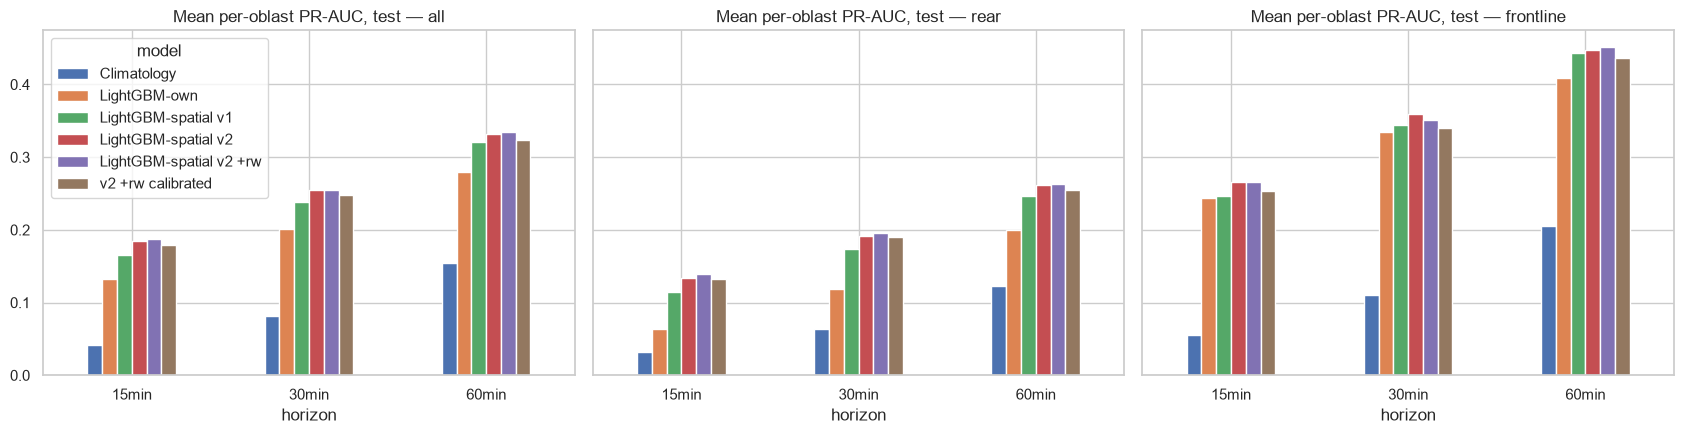

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for a, grp in zip(ax, ["all", "rear", "frontline"]):
    t = res.query("period=='test' and group==@grp").pivot(index="horizon", columns="model",
                                                         values="mean per-oblast PR-AUC").loc[list(HORIZONS), MODELS]
    t.plot(kind="bar", ax=a, rot=0, legend=(grp == "all"), title=f"Mean per-oblast PR-AUC, test — {grp}")
plt.tight_layout(); plt.show()

## 5. Significance: v2 +rw vs v1 and vs own (block bootstrap by day, per-oblast mean PR-AUC)

In [8]:
def bootstrap(P, a, b, cols, n=200, seed=0):
    P = P[P.index.get_level_values("oblast").isin(cols)].dropna()
    days = P.index.get_level_values("time").normalize()
    keys = days.unique(); groups = {d: np.where(days == d)[0] for d in keys}
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        s = P.iloc[np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])]
        s = s.reset_index(); s.index = pd.MultiIndex.from_arrays([np.arange(len(s)), s["oblast"]], names=["i", "oblast"])
        out.append(per_oblast_ap(s, a, cols) - per_oblast_ap(s, b, cols))
    return np.percentile(out, [2.5, 50, 97.5])

for h in HORIZONS:
    for b in ["LightGBM-own", "LightGBM-spatial v1"]:
        lo_, med, hi_ = bootstrap(preds[(h, "test")], "LightGBM-spatial v2 +rw", b, oblasts)
        print(f"{h}: v2+rw − {b:20s} = {med:+.3f}  [95% CI {lo_:+.3f}, {hi_:+.3f}]")

15min: v2+rw − LightGBM-own         = +0.061  [95% CI +0.040, +0.093]


15min: v2+rw − LightGBM-spatial v1  = +0.025  [95% CI +0.017, +0.036]


30min: v2+rw − LightGBM-own         = +0.059  [95% CI +0.039, +0.080]


30min: v2+rw − LightGBM-spatial v1  = +0.018  [95% CI +0.004, +0.032]


60min: v2+rw − LightGBM-own         = +0.054  [95% CI +0.033, +0.076]


60min: v2+rw − LightGBM-spatial v1  = +0.012  [95% CI +0.006, +0.019]


## 6. Per-oblast table (h = 30 min, test)

In [9]:
P = preds[("30min", "test")]
per = []
for o in oblasts:
    g = P.xs(o, level="oblast").dropna()
    if g.y.sum() < 5: continue
    per.append({"oblast": o, "group": "front" if o in FRONT else "rear", "base": g.y.mean(),
                **{m: average_precision_score(g.y, g[m]) for m in ["Climatology", "LightGBM-own",
                                                                     "LightGBM-spatial v1", "LightGBM-spatial v2 +rw"]}})
per = pd.DataFrame(per).set_index("oblast")
per["gain v2 vs v1"] = per["LightGBM-spatial v2 +rw"] - per["LightGBM-spatial v1"]
per.sort_values("gain v2 vs v1", ascending=False).round(3)

,group,base,Climatology,LightGBM-own,LightGBM-spatial v1,LightGBM-spatial v2 +rw,gain v2 vs v1
oblast,,,,,,,
Kyivska oblast,rear,0.080,0.083,0.197,0.241,0.295,0.055
Chernivetska oblast,rear,0.003,0.006,0.010,0.030,0.084,0.054
Dnipropetrovska oblast,front,0.018,0.027,0.289,0.235,0.275,0.040
Volynska oblast,rear,0.005,0.008,0.009,0.109,0.143,0.035
Kyiv City,rear,0.066,0.070,0.186,0.323,0.355,0.033
Donetska oblast,front,0.040,0.076,0.369,0.390,0.420,0.030
Khmelnytska oblast,rear,0.014,0.014,0.027,0.087,0.110,0.023
Vinnytska oblast,rear,0.034,0.033,0.076,0.099,0.121,0.022
Ternopilska oblast,rear,0.005,0.006,0.008,0.095,0.112,0.017


## 7. Feature importance (v2 +rw, h = 30 min)

own           0.352
oblast id     0.225
spatial v1    0.161
adjacency     0.088
calendar      0.067
raion         0.056
wave          0.049
dtype: float64


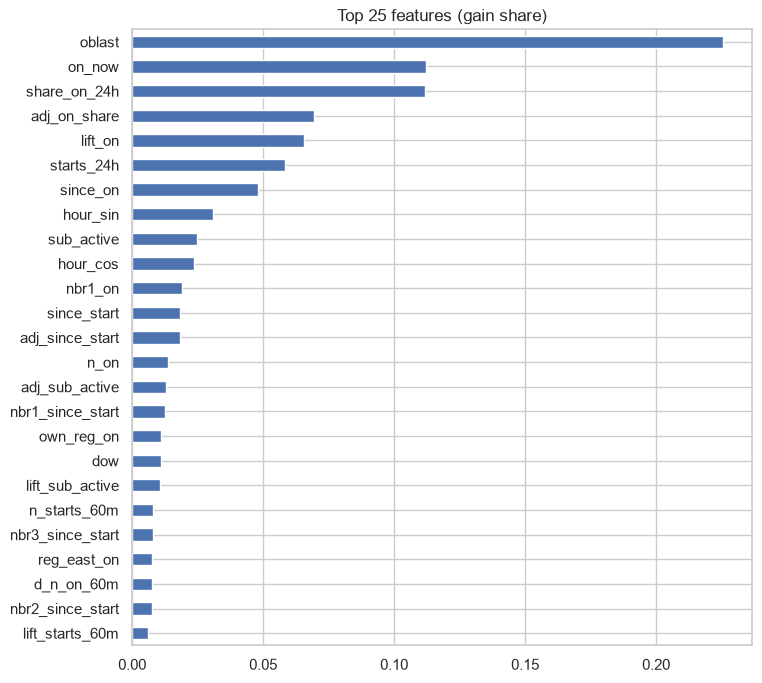

In [10]:
m = models["30min"]["LightGBM-spatial v2 +rw"]
imp = pd.Series(m.feature_importance("gain"), index=m.feature_name())
imp = (imp / imp.sum()).sort_values()
group_of = {f: g for g, fs in {"own": OWN, "calendar": CAL, "spatial v1": SPATIAL + nbr_cols(),
                               "wave": WAVE, "adjacency": ADJ_F, "raion": SUB}.items() for f in fs}
print(imp.groupby(lambda f: group_of.get(f, "oblast id")).sum().sort_values(ascending=False).round(3))
imp.tail(25).plot.barh(figsize=(8, 8), title="Top 25 features (gain share)"); plt.show()

## 8. Early warning with per-oblast thresholds

In [11]:
def thresholds(P, m, target_precision=0.5):
    thr = {}
    for o in oblasts:
        g = P.xs(o, level="oblast").dropna()
        if g.y.sum() < 5: continue
        pr, rc, th = precision_recall_curve(g.y, g[m])
        ok = np.where(pr[:-1] >= target_precision)[0]
        thr[o] = th[ok[0]] if len(ok) else np.inf          # never alarm if precision is unreachable
    return thr

def early_warning(m, h="60min", per_oblast=True):
    Pv, Pt = preds[(h, "val")], preds[(h, "test")]
    if per_oblast:
        thr = thresholds(Pv, m)
    else:
        g = Pv.dropna(); pr, rc, th = precision_recall_curve(g.y, g[m])
        t_ = th[np.where(pr[:-1] >= 0.5)[0][0]]; thr = {o: t_ for o in oblasts}
    rows = []
    for o in oblasts:
        p = Pt[m].xs(o, level="oblast")
        s = starts.loc[TEST:, o]; s = s[s == 1].index
        for ts in s:
            win = p.loc[ts - pd.Timedelta("60min"): ts - STEP]
            hit = win[win >= thr.get(o, np.inf)]
            rows.append({"oblast": o, "group": "front" if o in FRONT else "rear", "warned": len(hit) > 0,
                         "lead_min": (ts - hit.index[0] - STEP).total_seconds() / 60 if len(hit) else np.nan})
    return pd.DataFrame(rows)

ew = []
for m in ["LightGBM-own", "LightGBM-spatial v1", "LightGBM-spatial v2 +rw"]:
    for po in [False, True]:
        e = early_warning(m, per_oblast=po)
        ew.append({"model": m, "thresholds": "per-oblast" if po else "global",
                   "warned (all)": e.warned.mean(), "warned (rear)": e.query("group=='rear'").warned.mean(),
                   "median lead, min": e.lead_min.median()})
pd.DataFrame(ew).round(2)

,model,thresholds,warned (all),warned (rear),"median lead, min"
0,LightGBM-own,global,0.51,0.34,45.0
1,LightGBM-own,per-oblast,0.42,0.27,45.0
2,LightGBM-spatial v1,global,0.56,0.41,40.0
3,LightGBM-spatial v1,per-oblast,0.45,0.30,40.0
4,LightGBM-spatial v2 +rw,global,0.58,0.45,40.0
5,LightGBM-spatial v2 +rw,per-oblast,0.46,0.28,40.0


In [12]:
res.to_csv(DATA_DIR / "results_04_improved.csv", index=False)
print("saved")

saved


## Conclusions (fill in after running)
- New benchmark (mean per-oblast PR-AUC, 30 min, test): …
- Which feature groups helped: …
- Calibration: …
- Early warning with per-oblast thresholds: …